In [20]:
from pathlib import Path
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
DATA_PATH = Path.home() / "Datasets/luzern_raw.parquet"

con = duckdb.connect()

con.sql(f"""
    SELECT *
    FROM read_parquet('{DATA_PATH}')
    LIMIT 5
""").df()

,day,interval,detid,flow,occ,error,city,speed
0,2015-01-01,180,ig11FD208_D1,60,0.005,<NA>,luzern,None
1,2015-01-01,360,ig11FD208_D1,20,0.000,1,luzern,None
2,2015-01-01,540,ig11FD208_D1,100,0.010,<NA>,luzern,None
3,2015-01-01,720,ig11FD208_D1,200,0.025,<NA>,luzern,None
4,2015-01-01,900,ig11FD208_D1,120,0.015,<NA>,luzern,None


In [3]:
hourly = con.sql(f"""
    SELECT
        FLOOR(interval / 3600)::INTEGER AS hour,
        AVG(flow) AS avg_flow
    FROM read_parquet('{DATA_PATH}')
    WHERE error IS NULL
      AND flow IS NOT NULL
    GROUP BY hour
    ORDER BY hour
""").df()

hourly

,hour,avg_flow
0,0,134.695057
1,1,94.937343
2,2,67.823882
3,3,61.049867
4,4,68.469378
5,5,113.551067
6,6,263.034089
7,7,394.267381
8,8,383.602684
9,9,373.535818


**Opomba:** Pri analizi smo opazili dodatno uro `24`, čeprav so ure običajno označene od 0 do 23. Preverjanje je pokazalo 56.026 zapisov z vrednostjo `interval = 86400`, kar ustreza polnoči naslednjega dne. Ti zapisi so bili pri nadaljnji urni analizi začasno izključeni, dokler ne preverimo njihovega natančnega pomena.

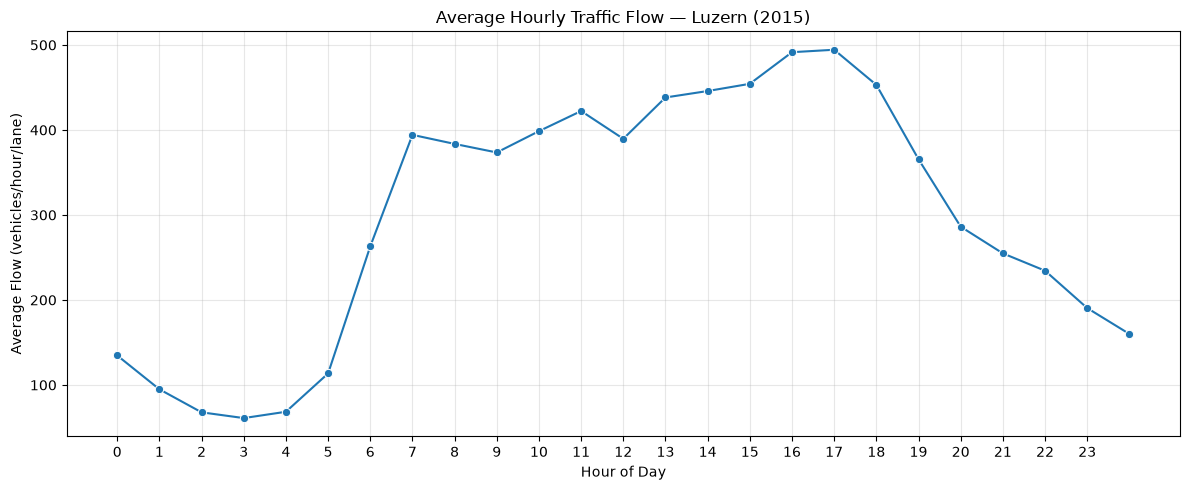

In [4]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=hourly,
    x="hour",
    y="avg_flow",
    marker="o"
)

plt.title("Average Hourly Traffic Flow — Luzern (2015)")
plt.xlabel("Hour of Day")
plt.ylabel("Average Flow (vehicles/hour/lane)")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [5]:
con.sql(f"""
    SELECT
        interval,
        COUNT(*) AS records,
        COUNT(DISTINCT detid) AS detectors
    FROM read_parquet('{DATA_PATH}')
    WHERE interval >= 86400
       OR interval < 0
    GROUP BY interval
    ORDER BY interval
""").df()

,interval,records,detectors
0,86400,56026,158


In [6]:
daily_patterns = con.sql(f"""
    SELECT
        FLOOR(interval / 3600)::INTEGER AS hour,
        CASE
            WHEN dayofweek(CAST(day AS DATE)) IN (0, 6)
            THEN 'Weekend'
            ELSE 'Weekday'
        END AS day_type,
        AVG(flow) AS avg_flow
    FROM read_parquet('{DATA_PATH}')
    WHERE error IS NULL
      AND flow IS NOT NULL
      AND interval >= 0
      AND interval < 86400
    GROUP BY hour, day_type
    ORDER BY hour, day_type
""").df()

daily_patterns.head()

,hour,day_type,avg_flow
0,0,Weekday,84.248657
1,0,Weekend,229.976617
2,1,Weekday,48.543911
3,1,Weekend,182.583919
4,2,Weekday,25.172758


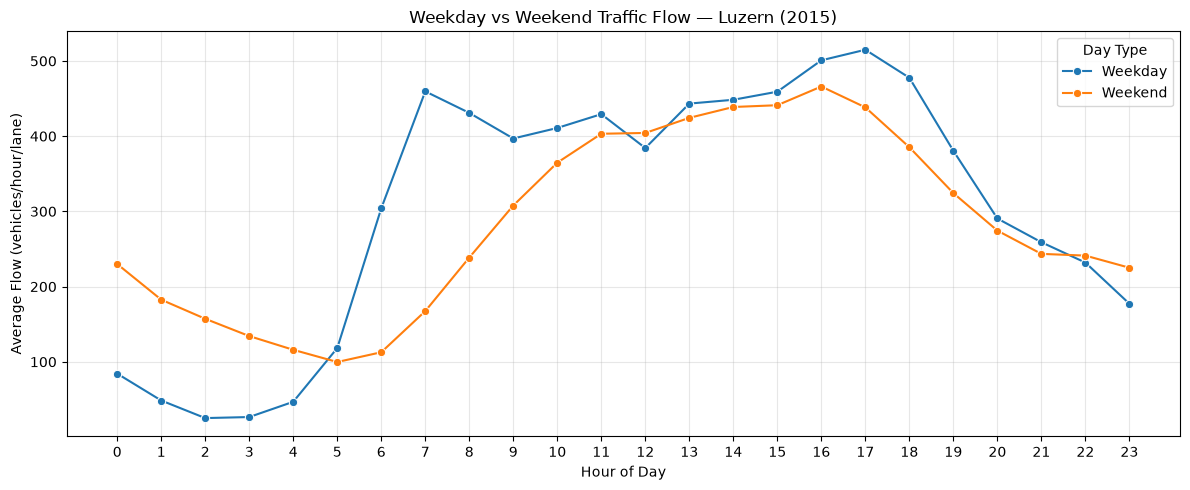

In [7]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=daily_patterns,
    x="hour",
    y="avg_flow",
    hue="day_type",
    marker="o"
)

plt.title("Weekday vs Weekend Traffic Flow — Luzern (2015)")
plt.xlabel("Hour of Day")
plt.ylabel("Average Flow (vehicles/hour/lane)")
plt.xticks(range(24))
plt.legend(title="Day Type")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
flow_occ = con.sql(f"""
    SELECT
        flow,
        occ,
        detid
    FROM read_parquet('{DATA_PATH}')
    WHERE error IS NULL
      AND flow IS NOT NULL
      AND occ IS NOT NULL
      AND flow >= 0
      AND occ BETWEEN 0 AND 1
    USING SAMPLE 50000 ROWS
""").df()

flow_occ.describe()

,flow,occ
count,33121.000000,33121.000000
mean,326.976480,0.071372
std,212.950442,0.080154
min,0.000000,0.000000
25%,160.000000,0.025000
50%,300.000000,0.050000
75%,460.000000,0.095000
max,1500.000000,0.985000


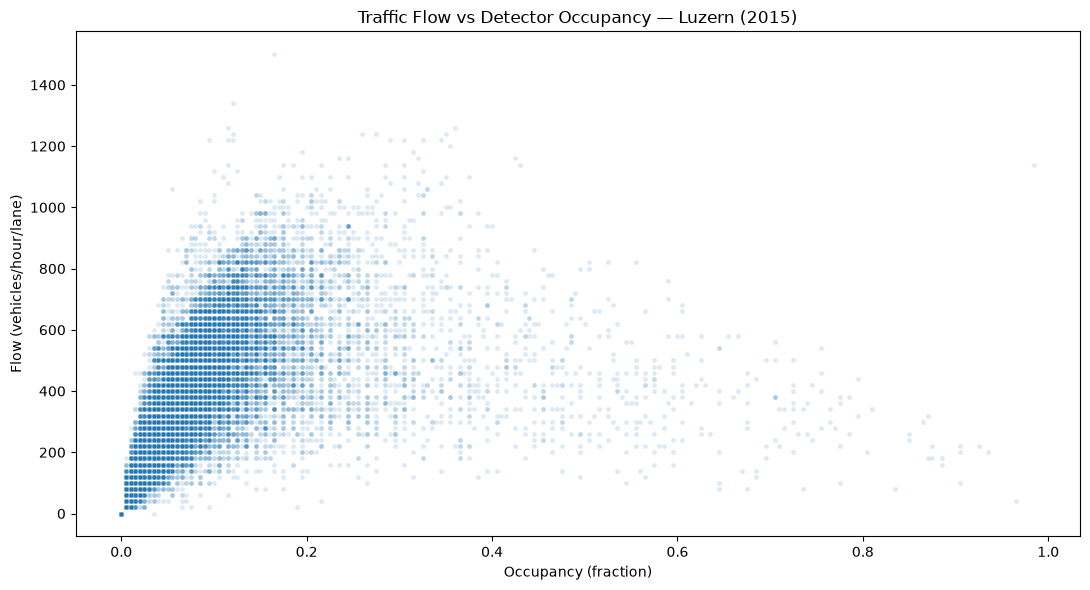

In [9]:
plt.figure(figsize=(11, 6))

sns.scatterplot(
    data=flow_occ,
    x="occ",
    y="flow",
    alpha=0.15,
    s=12
)

plt.title("Traffic Flow vs Detector Occupancy — Luzern (2015)")
plt.xlabel("Occupancy (fraction)")
plt.ylabel("Flow (vehicles/hour/lane)")
plt.tight_layout()
plt.show()

In [11]:
pearson = flow_occ["flow"].corr(
    flow_occ["occ"],
    method="pearson"
)

spearman = flow_occ["flow"].corr(
    flow_occ["occ"],
    method="spearman"
)

print(f"Pearson correlation:  {pearson:.4f}")
print(f"Spearman correlation: {spearman:.4f}")

Pearson correlation:  0.5684
Spearman correlation: 0.8611


In [12]:
from scipy.stats import spearmanr

correlations = []

for detid, group in flow_occ.groupby("detid"):
    if len(group) < 30:
        continue

    if group["flow"].nunique() < 2 or group["occ"].nunique() < 2:
        continue

    correlations.append({
        "detid": detid,
        "samples": len(group),
        "pearson": group["flow"].corr(group["occ"]),
        "spearman": spearmanr(group["flow"], group["occ"]).statistic
    })

sensor_corr = pd.DataFrame(correlations)

sensor_corr.sort_values("spearman").head(10)

,detid,samples,pearson,spearman
127,ig11FD211_D14,282,0.234327,0.675757
77,ig11FD117_D15,197,0.681431,0.735021
24,ig11FD106_D20,107,0.617364,0.740474
10,ig11FD100_D42,237,0.469478,0.748164
119,ig11FD205_D91,112,0.595369,0.766302
23,ig11FD106_D19,295,0.632100,0.805372
0,ig11FD100_D3,259,0.477135,0.809742
105,ig11FD203_D17,270,0.411816,0.832022
14,ig11FD104_D15,316,0.328105,0.837540
18,ig11FD105_D5,323,0.509144,0.839352


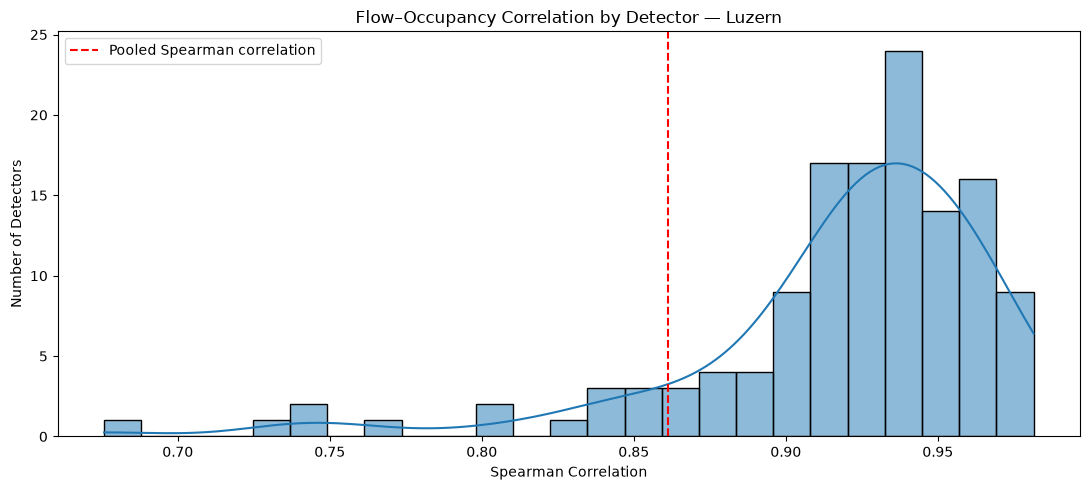

In [13]:
plt.figure(figsize=(11, 5))

sns.histplot(
    data=sensor_corr,
    x="spearman",
    bins=25,
    kde=True
)

plt.axvline(
    0.8611,
    color="red",
    linestyle="--",
    label="Pooled Spearman correlation"
)

plt.title("Flow–Occupancy Correlation by Detector — Luzern")
plt.xlabel("Spearman Correlation")
plt.ylabel("Number of Detectors")
plt.legend()
plt.tight_layout()
plt.show()

In [14]:
sensor_corr["spearman"].describe()

count    131.000000
mean       0.918461
std        0.051793
min        0.675757
25%        0.905029
50%        0.930527
75%        0.950791
max        0.981478
Name: spearman, dtype: float64

In [15]:
for threshold in [0.80, 0.90, 0.95]:
    count = (sensor_corr["spearman"] >= threshold).sum()
    percentage = count / len(sensor_corr) * 100

    print(
        f"Spearman >= {threshold}: "
        f"{count}/{len(sensor_corr)} detectors "
        f"({percentage:.1f}%)"
    )

Spearman >= 0.8: 126/131 detectors (96.2%)
Spearman >= 0.9: 102/131 detectors (77.9%)
Spearman >= 0.95: 35/131 detectors (26.7%)


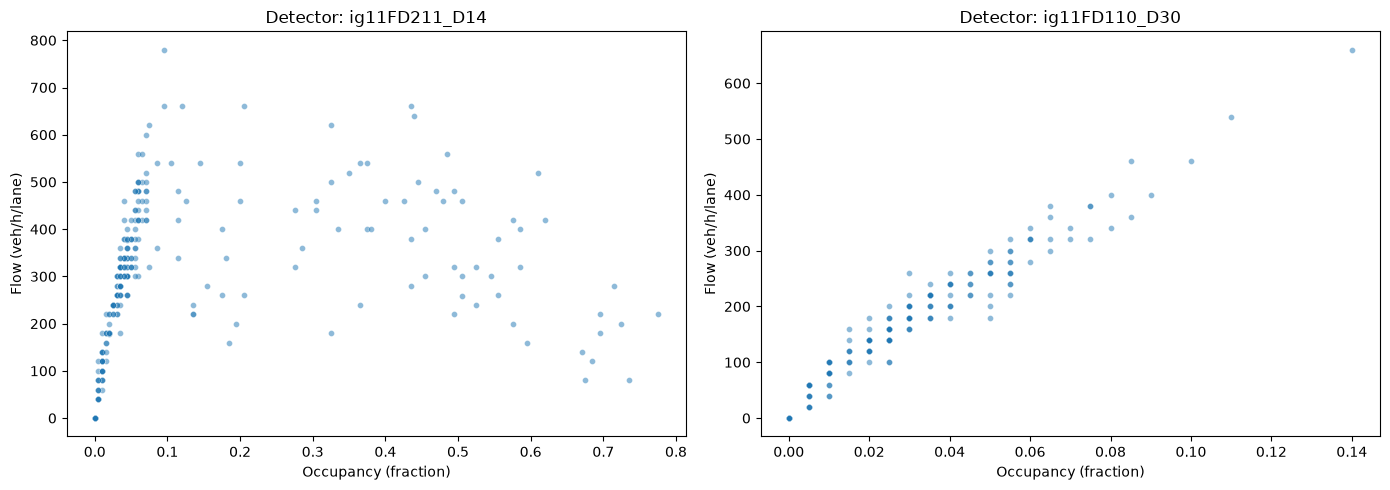

In [16]:
lowest = sensor_corr.loc[
    sensor_corr["spearman"].idxmin(), "detid"
]

highest = sensor_corr.loc[
    sensor_corr["spearman"].idxmax(), "detid"
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, detid in zip(axes, [lowest, highest]):
    data = flow_occ[flow_occ["detid"] == detid]

    sns.scatterplot(
        data=data,
        x="occ",
        y="flow",
        alpha=0.5,
        s=18,
        ax=ax
    )

    ax.set_title(f"Detector: {detid}")
    ax.set_xlabel("Occupancy (fraction)")
    ax.set_ylabel("Flow (veh/h/lane)")

plt.tight_layout()
plt.show()

In [17]:
detector_id = "ig11FD211_D14"

detector_data = con.sql("""
    SELECT
        day,
        interval,
        flow,
        occ
    FROM read_parquet(?)
    WHERE detid = ?
      AND error IS NULL
      AND flow IS NOT NULL
      AND occ BETWEEN 0 AND 1
      AND flow >= 0
    ORDER BY day, interval
""", params=[str(DATA_PATH), detector_id]).df()

print(f"Observations: {len(detector_data):,}")

print(
    "Pearson:",
    detector_data["flow"].corr(detector_data["occ"])
)

print(
    "Spearman:",
    detector_data["flow"].corr(
        detector_data["occ"], method="spearman"
    )
)

Observations: 144,883
Pearson: 0.24267789322500688
Spearman: 0.7074826754103836


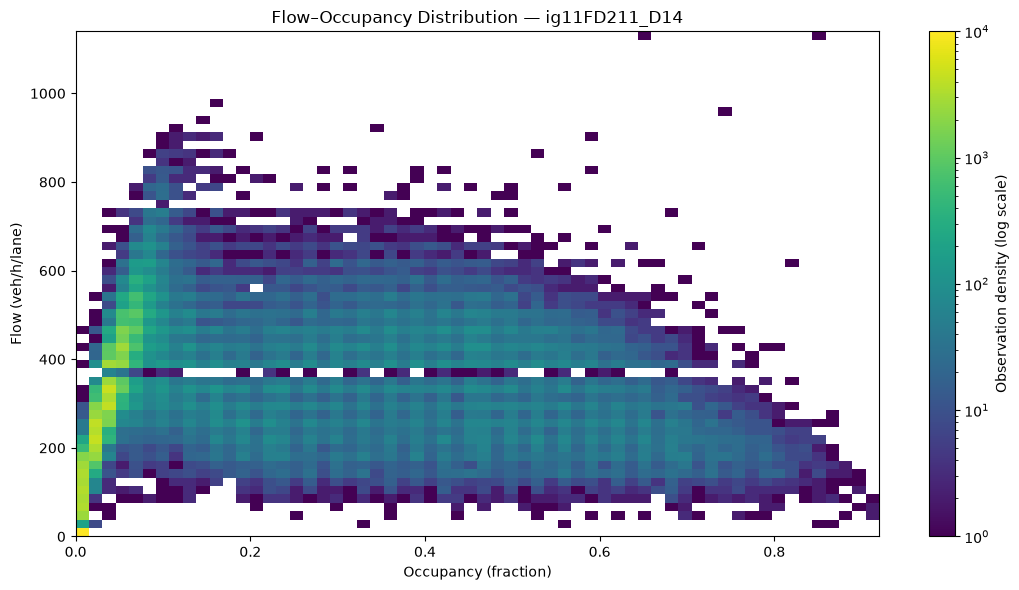

In [18]:
plt.figure(figsize=(11, 6))

plt.hist2d(
    detector_data["occ"],
    detector_data["flow"],
    bins=[60, 60],
    cmap="viridis",
    norm="log"
)

plt.colorbar(label="Observation density (log scale)")

plt.title(
    f"Flow–Occupancy Distribution — {detector_id}"
)
plt.xlabel("Occupancy (fraction)")
plt.ylabel("Flow (veh/h/lane)")
plt.tight_layout()
plt.show()

In [29]:
data = detector_data.copy()

data["occupancy_bin"] = pd.cut(
    data["occ"],
    bins=np.arange(0, 1.05, 0.05),
    include_lowest=True
)

binned = (
    data.groupby("occupancy_bin", observed=True)
    .agg(
        mean_flow=("flow", "mean"),
        median_flow=("flow", "median"),
        observations=("flow", "size")
    )
    .reset_index()
)

binned["occupancy_midpoint"] = (
    binned["occupancy_bin"]
    .apply(lambda x: x.mid)
    .astype(float)
)

display(binned)

,occupancy_bin,mean_flow,median_flow,observations,occupancy_midpoint
0,"(-0.001, 0.05]",211.943424,220.0,88890,0.0245
1,"(0.05, 0.1]",452.741776,440.0,20792,0.0750
2,"(0.1, 0.15]",416.611412,400.0,3873,0.1250
3,"(0.15, 0.2]",354.643909,340.0,2988,0.1750
4,"(0.2, 0.25]",340.388000,340.0,2750,0.2250
5,"(0.25, 0.3]",358.246023,360.0,2829,0.2750
6,"(0.3, 0.35]",371.962357,380.0,3055,0.3250
7,"(0.35, 0.4]",373.712658,380.0,3160,0.3750
8,"(0.4, 0.45]",367.213105,380.0,3205,0.4250
9,"(0.45, 0.5]",355.806369,360.0,3140,0.4750


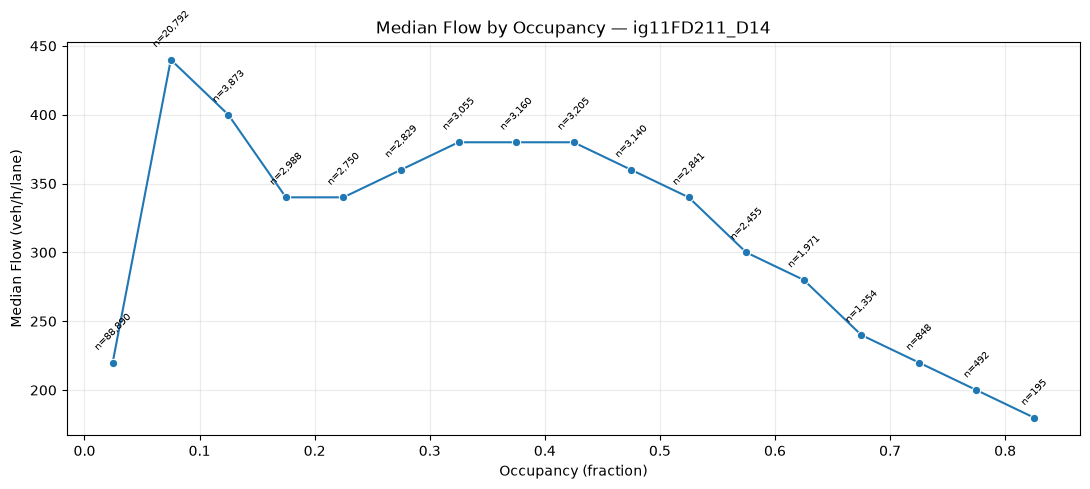

In [22]:
reliable_bins = binned[binned["observations"] >= 100].copy()

fig, ax = plt.subplots(figsize=(11, 5))

sns.lineplot(
    data=reliable_bins,
    x="occupancy_midpoint",
    y="median_flow",
    marker="o",
    ax=ax
)

for _, row in reliable_bins.iterrows():
    ax.annotate(
        f"n={int(row['observations']):,}",
        (row["occupancy_midpoint"], row["median_flow"]),
        xytext=(0, 9),
        textcoords="offset points",
        ha="center",
        fontsize=7,
        rotation=45
    )

ax.set_title(
    "Median Flow by Occupancy — ig11FD211_D14"
)
ax.set_xlabel("Occupancy (fraction)")
ax.set_ylabel("Median Flow (veh/h/lane)")
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

In [23]:
flow_counts = (
    detector_data["flow"]
    .value_counts()
    .sort_index()
)

display(
    flow_counts.loc[
        (flow_counts.index >= 300)
        & (flow_counts.index <= 460)
    ]
)

flow
300    8817
304       1
317       4
318      87
319      31
320    5428
334       1
335      14
337      19
338      98
339       6
340    8976
345       1
356       2
357       2
358     112
359       8
360    4949
374      14
376      15
377      20
378      93
379       4
380    8223
397      19
398      92
399       9
400    4465
412       1
414       4
416      27
417      28
418      69
419       5
420    6797
434       1
436       1
437      40
438      48
439       5
440    3401
451       1
453      12
456      16
457      35
458      29
459       3
460    5171
Name: count, dtype: int64

In [24]:
detector_data["hour"] = (
    detector_data["interval"] // 3600
)

hourly_distribution = (
    detector_data[
        detector_data["interval"].between(0, 86399)
    ]
    .groupby("hour")
    .agg(
        median_flow=("flow", "median"),
        median_occ=("occ", "median"),
        observations=("flow", "size")
    )
)

display(hourly_distribution)

,median_flow,median_occ,observations
hour,,,
0,80.0,0.005,3600
1,0.0,0.000,3757
2,0.0,0.000,3969
3,0.0,0.000,3533
4,40.0,0.005,2916
5,129.5,0.010,4728
6,360.0,0.040,6177
7,380.0,0.070,6617
8,360.0,0.070,6967


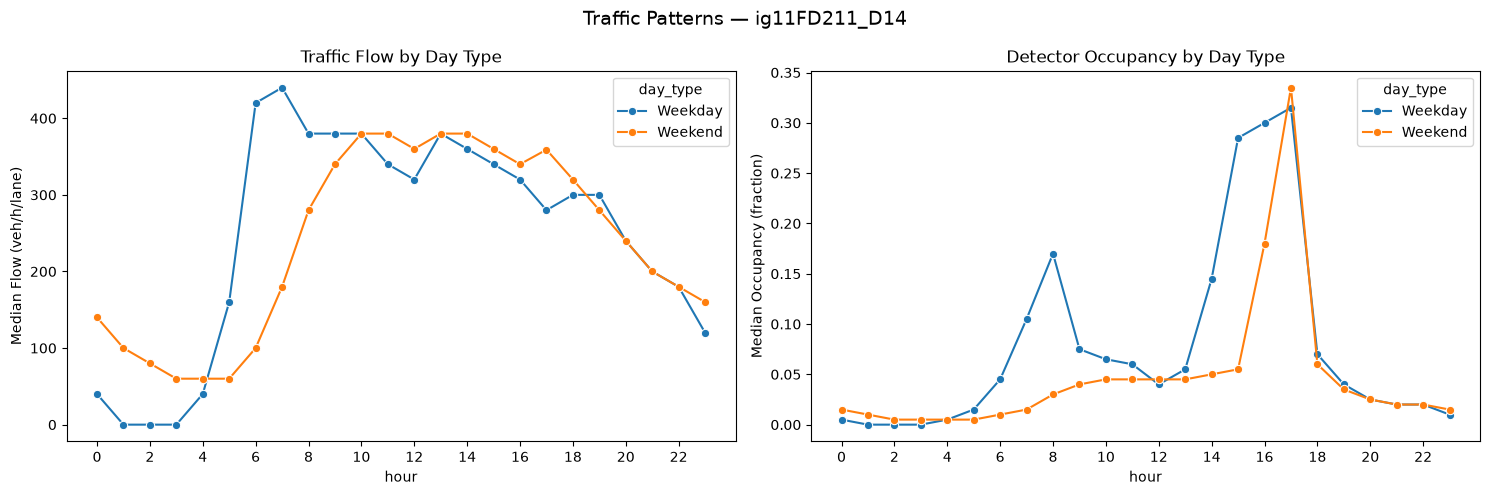

In [25]:
data = detector_data.copy()

data = data[
    (data["interval"] >= 0) &
    (data["interval"] < 86400)
].copy()

data["hour"] = data["interval"] // 3600

data["day_type"] = np.where(
    pd.to_datetime(data["day"]).dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

hourly = (
    data.groupby(["day_type", "hour"])
    .agg(
        median_flow=("flow", "median"),
        median_occ=("occ", "median"),
        observations=("flow", "size")
    )
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.lineplot(
    data=hourly,
    x="hour",
    y="median_flow",
    hue="day_type",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Traffic Flow by Day Type")
axes[0].set_ylabel("Median Flow (veh/h/lane)")
axes[0].set_xticks(range(0, 24, 2))

sns.lineplot(
    data=hourly,
    x="hour",
    y="median_occ",
    hue="day_type",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Detector Occupancy by Day Type")
axes[1].set_ylabel("Median Occupancy (fraction)")
axes[1].set_xticks(range(0, 24, 2))

plt.suptitle(
    "Traffic Patterns — ig11FD211_D14",
    fontsize=14
)

plt.tight_layout()
plt.show()

In [27]:
daily_hourly = (
    detector_data[
        detector_data["interval"].between(0, 86399)
    ]
    .copy()
)

daily_hourly["date"] = pd.to_datetime(daily_hourly["day"])
daily_hourly["hour"] = daily_hourly["interval"] // 3600

heatmap_data = (
    daily_hourly
    .groupby(["date", "hour"])["occ"]
    .median()
    .unstack()
    .reindex(columns=range(24))
)

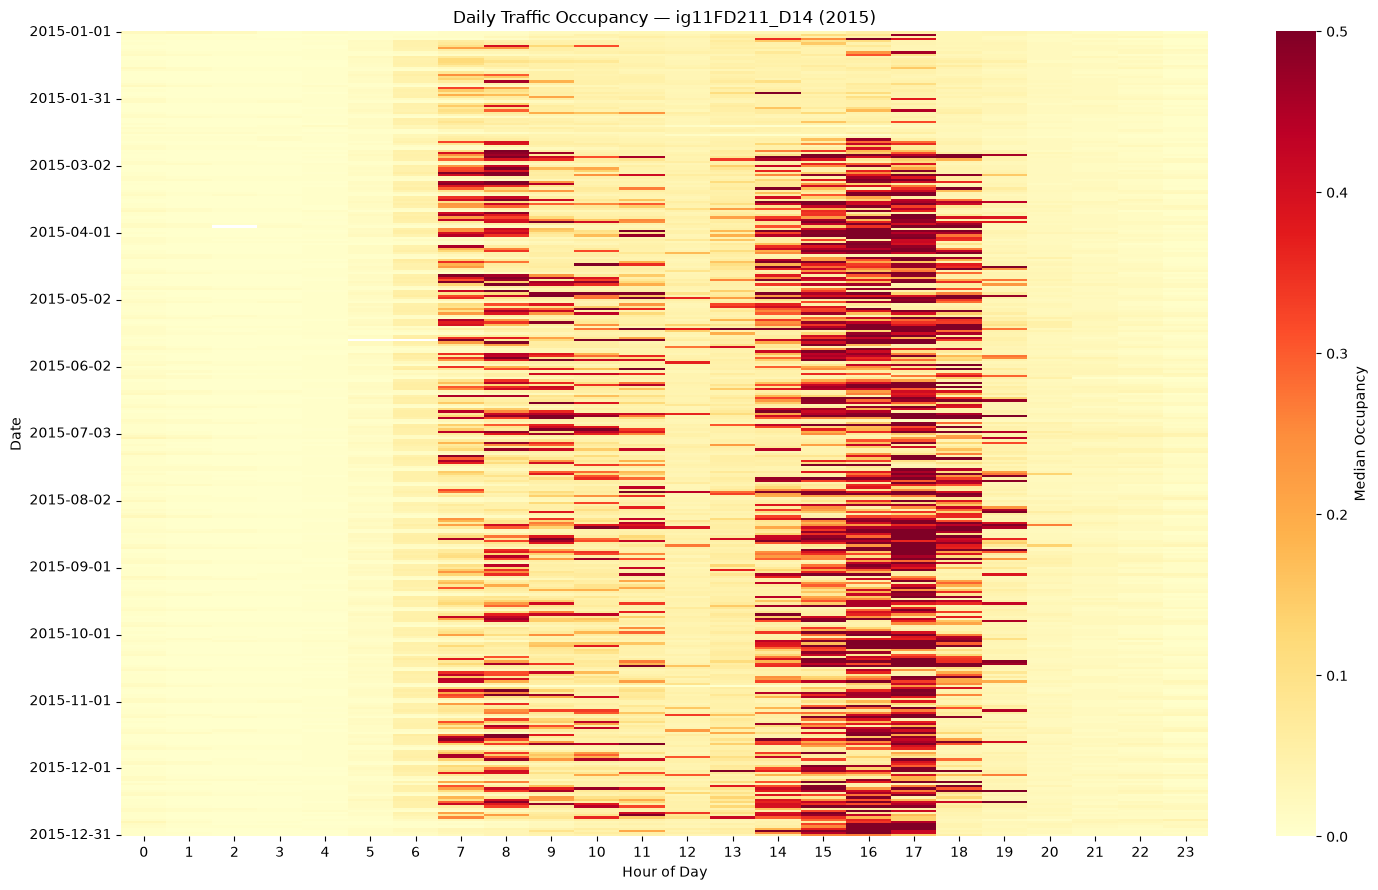

In [28]:
plt.figure(figsize=(15, 9))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    vmin=0,
    vmax=0.5,
    cbar_kws={"label": "Median Occupancy"}
)

plt.title(
    "Daily Traffic Occupancy — ig11FD211_D14 (2015)"
)
plt.xlabel("Hour of Day")
plt.ylabel("Date")

# Display approximately one date per month
ticks = range(0, len(heatmap_data), 30)

plt.yticks(
    [i + 0.5 for i in ticks],
    [
        heatmap_data.index[i].strftime("%Y-%m-%d")
        for i in ticks
    ],
    rotation=0
)

plt.tight_layout()
plt.show()